# Automatic chord recognition — Tiny AAM first

**Complete Google Colab demo:** Tiny AAM audio → BeatNet (isolated Python 3.9) → 24D bass/midrange CQT chroma → two shared multivariate Gaussians → transposition-invariant HMM → Viterbi.

The **main demo runs exclusively on Tiny AAM** (no full-AAM requests). At the end, an **optional section** trains a new model using a configurable number of larger AAM tracks, and lets you switch the active model for the same Tiny AAM demo.

**Scientific evaluation:** Train / validation / test are separate *songs*. Gaussian/HMM training uses annotated beats; BeatNet is used only when testing the complete audio-to-chords pipeline. The 89.53% reported in earlier work was for a different 80-song model using ground-truth beats; it is **not** the accuracy of this notebook until measured.

**Colab:** Run cells in order. Checkpoints/cache default to Google Drive if mounted; the notebook works without Drive too, but `/content` storage is temporary.

## 1. Setup and storage

We keep the main Colab kernel on its default Python version. Only BeatNet runs in the isolated Python 3.9 environment, matching the supplied working beat-tracking notebook. Drive mounting is optional.

In [1]:
%pip -q install librosa soundfile scikit-learn pandas matplotlib scipy remotezip
from pathlib import Path
import os, sys, re, io, csv, json, time, pickle, zipfile, shutil, subprocess
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
from scipy.stats import multivariate_normal
from sklearn.covariance import LedoitWolf
from sklearn.metrics import accuracy_score, f1_score
from IPython.display import display

USE_GOOGLE_DRIVE = True
if USE_GOOGLE_DRIVE:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        CACHE = Path('/content/drive/MyDrive/TinyAAM_Chord_Demo')
    except Exception as e:
        print('Drive unavailable; using temporary /content cache:', e)
        CACHE = Path('/content/TinyAAM_Chord_Demo')
else:
    CACHE = Path('/content/TinyAAM_Chord_Demo')
CACHE.mkdir(parents=True, exist_ok=True)
FEATURE_CACHE=CACHE/'features'; FEATURE_CACHE.mkdir(exist_ok=True)
BEAT_CACHE=CACHE/'beatnet'; BEAT_CACHE.mkdir(exist_ok=True)
FIG_CACHE=CACHE/'figures'; FIG_CACHE.mkdir(exist_ok=True)
MODEL_DIR=CACHE/'models'; MODEL_DIR.mkdir(exist_ok=True)

SEED=42; SR=22050; HOP=512
NOTES2=['C','C#','D','D#','E','F','F#','G','G#','A','A#','B']
CHORDS2=np.array([f'{n}{q}' for n in NOTES2 for q in ('maj','min')]); K=len(CHORDS2)
CHORD_TO_ID2={c:i for i,c in enumerate(CHORDS2)}
print('Persistent workspace:',CACHE)

Mounted at /content/drive
Persistent workspace: /content/drive/MyDrive/TinyAAM_Chord_Demo


## 2. Download and parse Tiny AAM

Uses the exact Tiny AAM archive and download method from your original notebook (`wget` and ZIP extraction), without opening the large full-AAM archive. Zenodo can occasionally return HTTP 504; a failed download should be retried after a short wait. **Never silently substitute another dataset.**

In [2]:
TINY_URL='https://zenodo.org/records/6771120/files/tinyAAM.zip'
TINY_ZIP=CACHE/'tinyAAM.zip'
TINY_ROOT=CACHE/'tinyAAM'
if not TINY_ZIP.exists() or not zipfile.is_zipfile(TINY_ZIP):
    TINY_ZIP.unlink(missing_ok=True)
    print('Downloading Tiny AAM (the only required dataset download)...')
    subprocess.run(['wget','--show-progress','--tries=3','--waitretry=5',TINY_URL,'-O',str(TINY_ZIP)],check=True)
if not zipfile.is_zipfile(TINY_ZIP):
    raise RuntimeError('Tiny AAM ZIP is missing or invalid; retry the download.')
if not list(TINY_ROOT.rglob('*_mix.mp3')):
    TINY_ROOT.mkdir(parents=True,exist_ok=True)
    with zipfile.ZipFile(TINY_ZIP) as z:z.extractall(TINY_ROOT)
audio_by_id={p.name.replace('_mix.mp3',''):p for p in TINY_ROOT.rglob('*_mix.mp3')}
ann_by_id={p.name.replace('_beatinfo.arff',''):p for p in TINY_ROOT.rglob('*_beatinfo.arff')}
TINY_IDS=sorted(set(audio_by_id)&set(ann_by_id))
print('Tiny AAM tracks with audio + annotations:',len(TINY_IDS))
print('Track IDs:',TINY_IDS)
if len(TINY_IDS)<8:raise RuntimeError('Expected at least 8 matched Tiny AAM tracks; inspect extracted files.')

Tiny AAM tracks with audio + annotations: 20
Track IDs: ['0001', '0080', '0192', '0620', '0758', '0989', '1014', '1050', '1545', '1711', '1941', '2269', '2395', '2462', '2602', '2720', '2828', '2841', '2990', '3000']


## 3. Read chord annotations and split songs

Tiny AAM is small, so we use approximately **60% training / 20% validation / 20% test**, with a reproducible saved split. The test songs remain excluded from fitting and hyperparameter selection. Unsupported or conflicting chord labels are marked `N` and omitted from 24-class accuracy.

In [3]:
# ============================================================
# CELL 4 — LOAD AND VALIDATE CHORD ANNOTATIONS
# ============================================================

def read_arff_beatinfo(data):
    """
    Parse AAM beatinfo ARFF files, including files
    without an explicit @DATA header.
    """
    lines = data.decode(
        "utf-8-sig", errors="replace"
    ).splitlines()

    rows = []

    for line in lines:
        line = line.strip()

        if not line or line.startswith(("@", "%")):
            continue

        fields = next(csv.reader(
            [line],
            quotechar="'",
            skipinitialspace=True
        ))

        if len(fields) < 4:
            continue

        try:
            time = float(fields[0])
        except ValueError:
            continue

        if not np.isfinite(time):
            continue

        chord = fields[3].strip().strip("'\"")
        rows.append((time, chord))

    if not rows:
        raise ValueError("No valid annotation rows found.")

    return sorted(rows, key=lambda x: x[0])


def normalize_chord(chord):
    """
    Map supported major/minor chord labels into our
    24-state vocabulary. Everything else becomes N.
    """
    chord = str(chord).strip().strip("'\"")

    if chord.lower() in {"n", "x", "?", "", "none"}:
        return "N"

    chord = chord.replace(":", "").replace("_", "")

    match = re.fullmatch(
        r"([A-Ga-g])([#b]?)(maj|min|m|M)?",
        chord
    )

    if not match:
        return "N"

    root = match.group(1).upper() + match.group(2)

    enharmonic = {
        "Db": "C#", "Eb": "D#", "Gb": "F#",
        "Ab": "G#", "Bb": "A#", "Cb": "B",
        "Fb": "E", "E#": "F", "B#": "C"
    }

    root = enharmonic.get(root, root)

    quality = (
        "min" if match.group(3) in ("min", "m")
        else "maj"
    )

    normalized = root + quality

    return normalized if normalized in CHORD_TO_ID2 else "N"

In [4]:
SPLIT_FILE=CACHE/'tiny_split_seed42.json'
if SPLIT_FILE.exists():
    split=json.loads(SPLIT_FILE.read_text())
    if set(split['train']+split['validation']+split['test'])!=set(TINY_IDS):
        raise RuntimeError('Tiny AAM track list differs from saved split; inspect before proceeding.')
else:
    shuffled=np.random.default_rng(SEED).permutation(TINY_IDS).tolist()
    n=len(shuffled)
    n_test=max(2,round(n*.2));n_val=max(2,round(n*.2))
    split={'train':shuffled[:n-n_test-n_val],
           'validation':shuffled[n-n_test-n_val:n-n_test],
           'test':shuffled[n-n_test:]}
    SPLIT_FILE.write_text(json.dumps(split,indent=2))
train_ids=split['train'];val_ids=split['validation'];test_ids=split['test']
assert not (set(train_ids)&set(val_ids) or set(train_ids)&set(test_ids) or set(val_ids)&set(test_ids))

def prepare_ann_data(raw_bytes_map):
    data={}
    for song,raw in raw_bytes_map.items():
        by_time={}
        for t,ch in read_arff_beatinfo(raw):
            by_time.setdefault(round(float(t),6),[]).append(normalize_chord(ch))
        cleaned=[(t,labels[0] if len(set(labels))==1 else 'N') for t,labels in sorted(by_time.items())]
        if len(cleaned)<8:raise ValueError(f'Song {song}: too few unique annotated beats')
        data[song]=(np.asarray([x[0] for x in cleaned],float),
                    np.asarray([x[1] for x in cleaned],dtype='<U8'))
    return data

ann_data=prepare_ann_data({s:ann_by_id[s].read_bytes() for s in TINY_IDS})
print('Train:',len(train_ids),train_ids)
print('Validation:',len(val_ids),val_ids)
print('Test:',len(test_ids),test_ids)
valid_count=sum(int(np.isin(ann_data[s][1],CHORDS2).sum()) for s in TINY_IDS)
print('Total scored major/minor beats:',valid_count)
display(pd.DataFrame({'time':ann_data[train_ids[0]][0][:8],'chord':ann_data[train_ids[0]][1][:8]}))

Train: 12 ['2720', '1711', '2602', '1050', '2395', '1941', '1014', '3000', '0620', '0001', '2828', '0989']
Validation: 4 ['2269', '2990', '0192', '0758']
Test: 4 ['2841', '0080', '2462', '1545']
Total scored major/minor beats: 5712


,time,chord
0,0.000000,Cmaj
1,0.504202,Cmaj
2,1.008403,Cmaj
3,1.512605,Cmaj
4,2.016807,Emin
5,2.521009,Emin
6,3.025210,Emin
7,3.529412,Emin


## 4. Audio → 24D CQT chroma

The CQT uses **84 semitones starting at C1**. We collapse C1–B3 into 12 bass chroma values and C4–B5 into 12 midrange values. Each feature vector averages the **central 90%** of a beat interval; both 12D bands are individually L2-normalized. This matches our established Gaussian/HMM feature specification.

In [5]:
def load_audio(song, keep=False):
    if song in audio_by_id:
        return librosa.load(str(audio_by_id[song]),sr=SR,mono=True)[0]
    return load_full_audio(song)

def compute_chroma24(y):
    """Exact source notebook implementation: CQT -> octave summation."""
    C=np.abs(librosa.cqt(y,sr=SR,hop_length=HOP,
        fmin=librosa.note_to_hz('C1'),n_bins=84,bins_per_octave=12)).astype(np.float32)
    bass=C[:36].reshape(3,12,-1).sum(axis=0)
    mid=C[36:60].reshape(2,12,-1).sum(axis=0)
    return np.concatenate([bass,mid],axis=0)

def features_from_times(chroma,starts,ends):
    """Identical to original training extractor, but supports any beat grid."""
    starts=np.asarray(starts,dtype=float);ends=np.asarray(ends,dtype=float)
    assert len(starts)==len(ends) and np.all(ends>starts)
    frame_times=librosa.frames_to_time(np.arange(chroma.shape[1]),sr=SR,hop_length=HOP)
    a=np.searchsorted(frame_times,starts+0.05*(ends-starts),side='left')
    b=np.searchsorted(frame_times,ends-0.05*(ends-starts),side='left')
    a=np.clip(a,0,chroma.shape[1]-1)
    b=np.clip(np.maximum(a+1,b),1,chroma.shape[1])
    cumul=np.concatenate([np.zeros((24,1),dtype=np.float64),
                          np.cumsum(chroma,axis=1,dtype=np.float64)],axis=1)
    X=(cumul[:,b]-cumul[:,a]).T/np.maximum(b-a,1)[:,None]
    for band in (slice(0,12),slice(12,24)):
        X[:,band]/=np.maximum(np.linalg.norm(X[:,band],axis=1,keepdims=True),1e-10)
    return X.astype(np.float32)


def extract_features(song):
    cache_file=FEATURE_CACHE/f'{song}_cqt24_sr{SR}_hop{HOP}.npz'
    if cache_file.exists():
        with np.load(cache_file) as z:return {k:z[k] for k in ('X','gt','t','dur','beat_idx')}
    y=load_audio(song)
    tt,gg=ann_data[song];duration=len(y)/SR
    typical=float(np.median(np.diff(tt)))
    end_all=np.r_[tt[1:],tt[-1]+typical]
    valid=(tt>=0)&(tt<duration-.01)
    idx=np.flatnonzero(valid);t=tt[valid];gt=gg[valid]
    ends=np.minimum(end_all[valid],duration)
    if len(t)<8 or np.any(ends<=t):raise ValueError(f'Invalid beat windows: {song}')
    X=features_from_times(compute_chroma24(y),t,ends)
    result=dict(X=X,gt=gt,t=t,dur=ends-t,beat_idx=idx)
    tmp=cache_file.with_suffix('.tmp.npz')
    np.savez_compressed(tmp,**result);tmp.replace(cache_file)
    return result

print('24D chroma extraction ready.')

24D chroma extraction ready.


## 5. Gaussian emission model

All major chords are rotated to root C and pooled into a single **24-dimensional multivariate Gaussian**; all minor chords form a second Gaussian. Each mean has 24 pitch-class strengths. **Ledoit–Wolf covariance shrinkage** models the variability and correlations across these features. For any candidate chord, we rotate its chroma relative to the candidate root and evaluate the corresponding Gaussian log-density.

In [6]:
# ============================================================
# CELL 7 — SHARED GAUSSIAN EMISSION MODEL
# ============================================================

def shift_to_C(X, root_index):
    """
    Rotate each 12D chroma band so that the
    candidate chord root becomes C.

    X: (N, 24)
    root_index: C=0, C#=1, ..., B=11
    """

    X = np.asarray(X)

    assert X.ndim == 2
    assert X.shape[1] == 24

    Z = X.reshape(-1, 2, 12)

    Z = np.roll(
        Z,
        -int(root_index),
        axis=2
    )

    return Z.reshape(-1, 24)


def fit_gaussian_emissions(songs):
    """
    Fit two shared Gaussian distributions:
        0: Major
        1: Minor

    Use only the supplied training songs.
    """

    samples = [[], []]

    for song in songs:

        data = extract_features(song)

        X = data["X"]
        gt = data["gt"]

        for root_index in range(12):

            for quality in range(2):

                chord = CHORDS2[
                    2 * root_index + quality
                ]

                mask = gt == chord

                if not np.any(mask):
                    continue

                aligned = shift_to_C(
                    X[mask],
                    root_index
                )

                samples[quality].append(aligned)

    gaussians = []
    sample_counts = []

    for quality in range(2):

        if not samples[quality]:
            raise ValueError(
                f"No samples for quality {quality}"
            )

        Z = np.vstack(samples[quality]).astype(
            np.float64
        )

        if len(Z) < 50:
            raise ValueError(
                f"Too few samples for quality {quality}: {len(Z)}"
            )

        estimator = LedoitWolf()
        estimator.fit(Z)

        mu = estimator.location_
        cov = estimator.covariance_ + 1e-4 * np.eye(24)

        gaussians.append((mu, cov))
        sample_counts.append(len(Z))

    return {
        "gaussians": gaussians,
        "sample_counts": sample_counts,
        "training_songs": list(songs)
    }


def emission_scores(X, model):
    """
    Compute log likelihoods for all 24 chords.

    Input:
        X: (N, 24)

    Output:
        scores: (N, 24)

    Each score is log p(X_t | chord).
    """

    X = np.asarray(X)

    scores = np.empty(
        (len(X), 24),
        dtype=np.float64
    )

    for root_index in range(12):

        aligned = shift_to_C(
            X,
            root_index
        )

        for quality in range(2):

            j = 2 * root_index + quality

            mu, cov = model["gaussians"][quality]

            scores[:, j] = multivariate_normal.logpdf(
                aligned,
                mean=mu,
                cov=cov
            )

    return scores


# ------------------------------------------------------------
# Unit tests
# ------------------------------------------------------------

test_X = np.zeros((1, 24))
test_X[0, 2] = 1.0   # D in bass band
test_X[0, 14] = 1.0  # D in mid band

rotated = shift_to_C(test_X, root_index=2)

assert rotated[0, 0] == 1.0
assert rotated[0, 12] == 1.0

assert rotated.shape == (1, 24)

print("=== CELL 7 CHECK ===")
print("Chroma transposition test: PASSED")
print("Gaussian fitting function: READY")
print("Emission scoring function: READY")
print("\nCell 7 completed successfully.")

=== CELL 7 CHECK ===
Chroma transposition test: PASSED
Gaussian fitting function: READY
Emission scoring function: READY

Cell 7 completed successfully.


## 6. Learned HMM and weighted Viterbi

The HMM contains 24 chord states. Its 24×24 transition matrix is learned by pooling transitions according to **previous quality, root movement (0–11 semitones), and next quality**. There are 48 shared transition categories. Viterbi chooses the best **whole-song sequence**, so later beats can correct the first beat.

**Known limitation:** It cannot distinguish harmonic function (e.g. I→IV versus V→I in the same key) because those progressions have the same relative root interval and qualities.

In [7]:
# ============================================================
# CELL 10 — HMM TRANSITIONS AND VITERBI
# ============================================================

def learn_relative_transitions(songs, smoothing=0.5):
    """
    Learn P(next root interval, next quality |
            previous quality).

    Shape: (2, 12, 2)
      axis 0: previous quality (major/minor)
      axis 1: root interval modulo 12
      axis 2: next quality (major/minor)

    Uses only consecutive annotated beats and skips
    transitions involving unsupported chord labels.
    """

    counts = np.full(
        (2, 12, 2),
        smoothing,
        dtype=np.float64
    )

    for song in songs:

        times, chords = ann_data[song]

        for t in range(1, len(chords)):
            previous = chords[t - 1]
            current = chords[t]

            if (
                previous not in CHORD_TO_ID2
                or current not in CHORD_TO_ID2
            ):
                continue

            i = CHORD_TO_ID2[previous]
            j = CHORD_TO_ID2[current]

            prev_root = i // 2
            next_root = j // 2

            prev_quality = i % 2
            next_quality = j % 2

            interval = (next_root - prev_root) % 12

            counts[
                prev_quality,
                interval,
                next_quality
            ] += 1

    relative_probs = counts / counts.sum(
        axis=(1, 2),
        keepdims=True
    )

    # Expand relative probabilities into a 24x24 matrix.
    A = np.zeros((24, 24), dtype=np.float64)

    for i in range(24):
        for j in range(24):

            interval = (
                (j // 2) - (i // 2)
            ) % 12

            A[i, j] = relative_probs[
                i % 2,
                interval,
                j % 2
            ]

    assert np.allclose(A.sum(axis=1), 1.0)
    assert np.all(A > 0)

    return {
        "A": A,
        "relative_probs": relative_probs,
        "counts": counts
    }


def simple_transition_matrix(stay=0.85):
    """
    Baseline:
      P(same chord) = stay
      Remaining probability spread uniformly.
    """

    A = np.full(
        (K, K),
        (1 - stay) / (K - 1),
        dtype=np.float64
    )

    np.fill_diagonal(A, stay)

    return A


def viterbi(log_emissions, A, weight=1.0):
    """
    Find the most likely chord sequence using Viterbi.

    weight controls the influence of transitions:
        0.0 = independent emission predictions
        1.0 = ordinary HMM
        >1  = stronger transition preference
    """

    T, n_states = log_emissions.shape

    if T == 0:
        return np.array([], dtype=int)

    assert A.shape == (n_states, n_states)

    log_A = weight * np.log(
        np.maximum(A, 1e-300)
    )

    dp = np.empty(
        (T, n_states),
        dtype=np.float64
    )

    back = np.zeros(
        (T, n_states),
        dtype=np.int16
    )

    # Uniform initial chord prior
    dp[0] = (
        log_emissions[0]
        - np.log(n_states)
    )

    for t in range(1, T):

        candidates = (
            dp[t - 1, :, None]
            + log_A
        )

        back[t] = np.argmax(
            candidates,
            axis=0
        )

        dp[t] = (
            log_emissions[t]
            + candidates[
                back[t],
                np.arange(n_states)
            ]
        )

    path = np.empty(T, dtype=np.int16)

    path[-1] = np.argmax(dp[-1])

    for t in range(T - 2, -1, -1):
        path[t] = back[
            t + 1,
            path[t + 1]
        ]

    return path



print("HMM transition estimator and Viterbi ready.")

HMM transition estimator and Viterbi ready.


## 7. Train the Tiny AAM model and tune on validation songs

Gaussian and transitions are trained **only** on Tiny AAM training songs. We choose the HMM transition weight **only using validation songs**; no test labels are used for tuning. Because Tiny AAM is small, expect noticeable variance from song to song. The model is checkpointed so subsequent sessions can load it quickly.

In [8]:
TINY_CHECKPOINT=MODEL_DIR/'tiny_gaussian_hmm.pkl'
WEIGHT_GRID=[0.5,1.0,2.0,4.0,6.0,8.0]

def choose_weight(gaussian,A,ids):
    song_scores={w:[] for w in WEIGHT_GRID}
    for s in ids:
        d=extract_features(s);mask=np.isin(d['gt'],CHORDS2)
        if mask.sum()==0:continue
        scores=emission_scores(d['X'],gaussian)
        for w in WEIGHT_GRID:
            p=CHORDS2[viterbi(scores,A,w)]
            song_scores[w].append((int(np.sum(p[mask]==d['gt'][mask])),int(mask.sum())))
    totals={w:sum(a for a,b in counts)/max(1,sum(b for a,b in counts)) for w,counts in song_scores.items()}
    return max(totals,key=totals.get),totals

if TINY_CHECKPOINT.exists():
    with open(TINY_CHECKPOINT,'rb') as f:tiny_model=pickle.load(f)
    if tiny_model['training_songs']!=train_ids or tiny_model['test_songs']!=test_ids:
        raise RuntimeError('Saved Tiny AAM model does not match the current split.')
    print('Loaded saved Tiny AAM model.')
else:
    gaussian=fit_gaussian_emissions(train_ids)
    transitions=learn_relative_transitions(train_ids,smoothing=.5)
    weight,validation_grid=choose_weight(gaussian,transitions['A'],val_ids)
    tiny_model=dict(gaussian=gaussian,transition=transitions,A_simple=simple_transition_matrix(.85),
        learned_weight=float(weight),validation_grid=validation_grid,
        training_songs=list(train_ids),validation_songs=list(val_ids),test_songs=list(test_ids),
        chords=CHORDS2.copy(),sr=SR,hop=HOP)
    tmp=TINY_CHECKPOINT.with_suffix('.tmp')
    with open(tmp,'wb') as f:pickle.dump(tiny_model,f)
    tmp.replace(TINY_CHECKPOINT)
    print('Saved Tiny AAM model:',TINY_CHECKPOINT)
print('Best validation weight:',tiny_model['learned_weight'])
print('Gaussian training examples by quality:',tiny_model['gaussian']['sample_counts'])
print('Validation grid:',tiny_model['validation_grid'])

# Active model: optional full-data section below can change this later.
MODEL_CHOICE='tiny'
ACTIVE_MODEL=tiny_model
GAUSSIAN=ACTIVE_MODEL['gaussian'];A_LEARNED=ACTIVE_MODEL['transition']['A']
WEIGHT=ACTIVE_MODEL['learned_weight']

Saved Tiny AAM model: /content/drive/MyDrive/TinyAAM_Chord_Demo/models/tiny_gaussian_hmm.pkl
Best validation weight: 4.0
Gaussian training examples by quality: [1778, 1734]
Validation grid: {0.5: 0.8293795620437956, 1.0: 0.843065693430657, 2.0: 0.8567518248175182, 4.0: 0.8585766423357665, 6.0: 0.8403284671532847, 8.0: 0.8293795620437956}


## 8. Visualize learned musical distributions

The average C-major pattern should emphasize C, E, G; minor should emphasize C, E♭, G. These are **learned means**, not hand-coded templates; the bass and midrange can show different strengths.

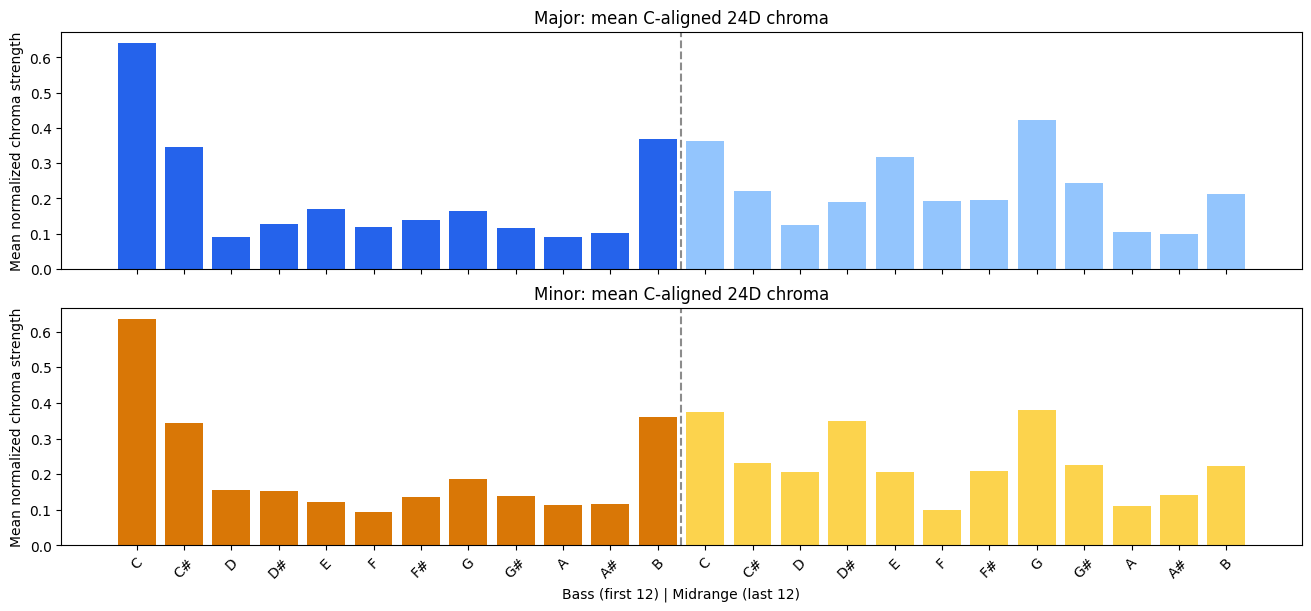

In [9]:
fig,axs=plt.subplots(2,1,figsize=(13,6),sharex=True,layout='constrained')
labels=NOTES2+NOTES2
for q,(name,col) in enumerate([('Major','#2563eb'),('Minor','#d97706')]):
    mean,_=ACTIVE_MODEL["gaussian"]['gaussians'][q]
    axs[q].bar(np.arange(24),mean,color=[col]*12+['#93c5fd' if q==0 else '#fcd34d']*12)
    axs[q].axvline(11.5,color='black',ls='--',alpha=.45)
    axs[q].set_title(f'{name}: mean C-aligned 24D chroma')
    axs[q].set_ylabel('Mean normalized chroma strength')
axs[1].set_xticks(range(24),labels,rotation=45)
axs[1].set_xlabel('Bass (first 12) | Midrange (last 12)')
plt.show()

## 9. BeatNet (Python 3.9 isolated environment)

Reuse the working dependencies from the original Tiny AAM BeatNet notebook. This installation is only needed once per fresh Colab runtime. The pretrained BeatNet offline DBN model runs in a separate subprocess, so it does not conflict with modern Colab's Python.

In [10]:
# Run once per fresh Colab runtime; /content/beatnet39 is temporary.
if not Path('/content/beatnet39/bin/python').exists():
    subprocess.run([sys.executable,'-m','pip','install','-q','uv'],check=True)
    subprocess.run(['uv','python','install','3.9'],check=True)
    subprocess.run(['uv','venv','/content/beatnet39','--python','3.9','--seed'],check=True)
subprocess.run(['apt-get','-qq','update'],check=True)
subprocess.run(['apt-get','-qq','install','-y','portaudio19-dev'],check=True)
PIP='/content/beatnet39/bin/pip'
subprocess.run([PIP,'install','-q','--upgrade','pip','wheel'],check=True)
subprocess.run([PIP,'install','-q','setuptools<81','numpy==1.23.5','numba==0.57.1',
 'llvmlite==0.40.1','cython','scipy','mido','librosa','torch','matplotlib',
 'tensorboard','pyyaml','pyaudio'],check=True)
subprocess.run([PIP,'install','-q','--no-build-isolation','--no-cache-dir','madmom==0.16.1'],check=True)
subprocess.run([PIP,'install','-q','--no-deps','BeatNet'],check=True)
print('BeatNet Python:',subprocess.check_output(['/content/beatnet39/bin/python','--version'],text=True).strip())

BeatNet Python: Python 3.9.25


## 10. Run BeatNet and cache predictions

BeatNet predicts beat timestamps from **audio alone**. It never receives the annotation file. Chords are then extracted at BeatNet intervals and decoded by our HMM.

In [11]:
BEATNET_SCRIPT=Path('/content/run_beatnet_aam.py')
BEATNET_SCRIPT.write_text(r'''import os,sys,numpy as np
os.environ['MPLBACKEND']='Agg'
from BeatNet.BeatNet import BeatNet
input_path, output_path=sys.argv[1:3]
model=BeatNet(1,mode='offline',inference_model='DBN',plot=[],thread=False)
raw=np.asarray(model.process(input_path))
if raw.ndim!=2 or raw.shape[1]<2:
    raise RuntimeError('Unexpected BeatNet output shape: '+str(raw.shape))
np.savez_compressed(output_path,events=raw)
print('BeatNet:',len(raw),'beats written to',output_path)
''')

def detect_beats_beatnet(song, audio_path):
    path=BEAT_CACHE/f'{song}_beatnet.npz'
    if not path.exists():
        subprocess.run(['/content/beatnet39/bin/python',str(BEATNET_SCRIPT),str(audio_path),str(path)],
             check=True,env={**os.environ,'MPLBACKEND':'Agg'})
    with np.load(path) as z:events=z['events']
    times=np.unique(events[:,0].astype(float))
    return times,events
print('BeatNet subprocess runner ready.')

BeatNet subprocess runner ready.


## 11. Test complete system on held-out Tiny AAM songs

Select up to three test tracks (set `N_DEMO`), and compare **the same HMM** when supplied with annotated versus BeatNet beat times. Time-aligned chord accuracy is measured at 50 ms intervals because the beat grids differ. Predictions and figures are saved. The main run never uses full-AAM data.

In [12]:
N_DEMO=3
rng=np.random.default_rng(2026)
SELECTED=rng.choice(test_ids,size=min(N_DEMO,len(test_ids)),replace=False).tolist()
print('Tiny AAM held-out songs:', SELECTED)

def time_labels(q,starts,ends,labels):
    ii=np.searchsorted(starts,q,side='right')-1
    out=np.full(len(q),'N',dtype='<U16')
    good=(ii>=0)&(ii<len(labels))
    ii=np.clip(ii,0,len(labels)-1)
    good &= q < ends[ii]
    out[good]=np.asarray(labels)[ii[good]]
    return out

def time_accuracy(gt_start,gt_end,gt,p_start,p_end,p):
    # 50-ms grid including all annotated song time; uncovered predictions -> incorrect
    ts=np.arange(gt_start[0],gt_end[-1],.05)+.025
    yt=time_labels(ts,gt_start,gt_end,gt)
    yp=time_labels(ts,p_start,p_end,p)
    mask=np.isin(yt,CHORDS2)
    return float(np.mean(yt[mask]==yp[mask])),float(np.mean(yp[mask]!='N'))

def match_beats(gt,pred,tol=.07):
    gt=np.asarray(gt);pred=np.asarray(pred)
    if not len(gt) or not len(pred):return 0.,0.,0.
    # Efficient sorted one-to-one greedy matching for 1D timestamps at fixed tolerance
    i=j=matched=0
    while i<len(gt) and j<len(pred):
        if abs(gt[i]-pred[j])<=tol:matched+=1;i+=1;j+=1
        elif gt[i]<pred[j]:i+=1
        else:j+=1
    precision=matched/len(pred);recall=matched/len(gt)
    f1=2*precision*recall/(precision+recall) if precision+recall else 0.
    return precision,recall,f1

def predicted_intervals(times,audio_dur):
    t=np.unique(np.asarray(times,dtype=float))
    t=t[np.isfinite(t)&(t>=0)&(t<audio_dur-.02)]
    if len(t)<4:raise RuntimeError('Too few beats to decode.')
    ends=np.r_[t[1:],audio_dur]
    return t,ends

def run_demo(selected=None):
    global RESULTS, RESULT_CACHE
    if selected is None:selected=SELECTED
    RESULT_CACHE=CACHE/'end_to_end'/MODEL_CHOICE;RESULT_CACHE.mkdir(parents=True,exist_ok=True)
    RESULTS=[]
    for song in selected:
        print('\n=======',song,'=======')
        path=audio_by_id[song]
        y=load_audio(song)
        duration=len(y)/SR
        gt_t,gt_labels=ann_data[song]
        typical=float(np.median(np.diff(gt_t)))
        gt_ends=np.minimum(np.r_[gt_t[1:],gt_t[-1]+typical],duration)
        valid=(gt_t>=0)&(gt_t<duration-.01)&(gt_ends>gt_t)
        gt_t=gt_t[valid];gt_ends=gt_ends[valid];gt_labels=gt_labels[valid]
        print('Running BeatNet (or loading cached beats)...')
        detected,events=detect_beats_beatnet(song,path)
        pred_t,pred_ends=predicted_intervals(detected,duration)
        print('Computing shared CQT...')
        chroma=compute_chroma24(y)
        X_oracle=features_from_times(chroma,gt_t,gt_ends)
        X_pred=features_from_times(chroma,pred_t,pred_ends)
        def decode(X):
            scores=emission_scores(X,GAUSSIAN)
            return CHORDS2[viterbi(scores,A_LEARNED,WEIGHT)]
        oracle=decode(X_oracle);pred=decode(X_pred)
        oracle_acc,_=time_accuracy(gt_t,gt_ends,gt_labels,gt_t,gt_ends,oracle)
        actual_acc,coverage=time_accuracy(gt_t,gt_ends,gt_labels,pred_t,pred_ends,pred)
        # Restrict beat comparison to annotated beat range
        compare_beats=pred_t[(pred_t>=gt_t[0])&(pred_t<=gt_t[-1])]
        bp,br,bf1=match_beats(gt_t,compare_beats)
        res=dict(song=song,gt_start=gt_t,gt_end=gt_ends,gt=gt_labels,
           oracle=oracle,pred_start=pred_t,pred_end=pred_ends,pred=pred,
           beat_precision=bp,beat_recall=br,beat_f1=bf1,
           oracle_accuracy=oracle_acc,end_to_end_accuracy=actual_acc,coverage=coverage)
        RESULTS.append(res)
        with open(RESULT_CACHE/f'{song}_result.pkl','wb') as f:pickle.dump(res,f)
        print(f'BeatNet beat F1={bf1:.1%} | HMM annotated beats={oracle_acc:.1%} | BeatNet + HMM={actual_acc:.1%}')
    print('Finished all',len(RESULTS),'songs.')

run_demo()

Tiny AAM held-out songs: ['1545', '0080', '2841']

======= 1545 =======
Running BeatNet (or loading cached beats)...
Computing shared CQT...
BeatNet beat F1=99.8% | HMM annotated beats=82.4% | BeatNet + HMM=82.5%

======= 0080 =======
Running BeatNet (or loading cached beats)...
Computing shared CQT...
BeatNet beat F1=83.6% | HMM annotated beats=98.6% | BeatNet + HMM=95.2%

======= 2841 =======
Running BeatNet (or loading cached beats)...
Computing shared CQT...
BeatNet beat F1=74.7% | HMM annotated beats=98.3% | BeatNet + HMM=96.0%
Finished all 3 songs.


## 12. Full-song plots, 30-second excerpts, and performance table

All three chord tracks show **real timestamps** rather than matching beat numbers. Same hue means same chord class. Do not compare Tiny AAM demo metrics directly with the earlier 89.53% number: that was a different train/test split and annotated-beat-only evaluation.


SONG 1545
BeatNet beat F1: 99.8% | Oracle HMM: 82.4% | Full pipeline: 82.5%


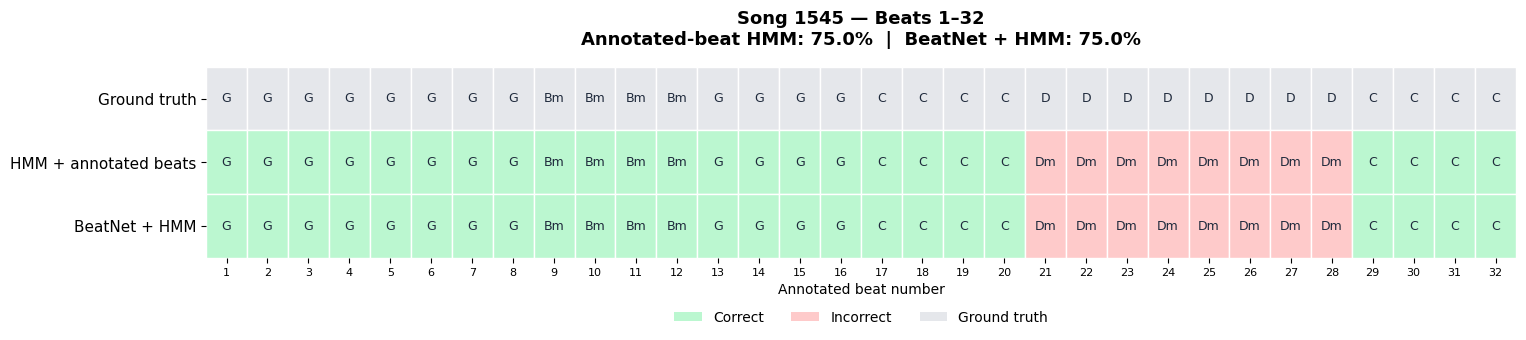

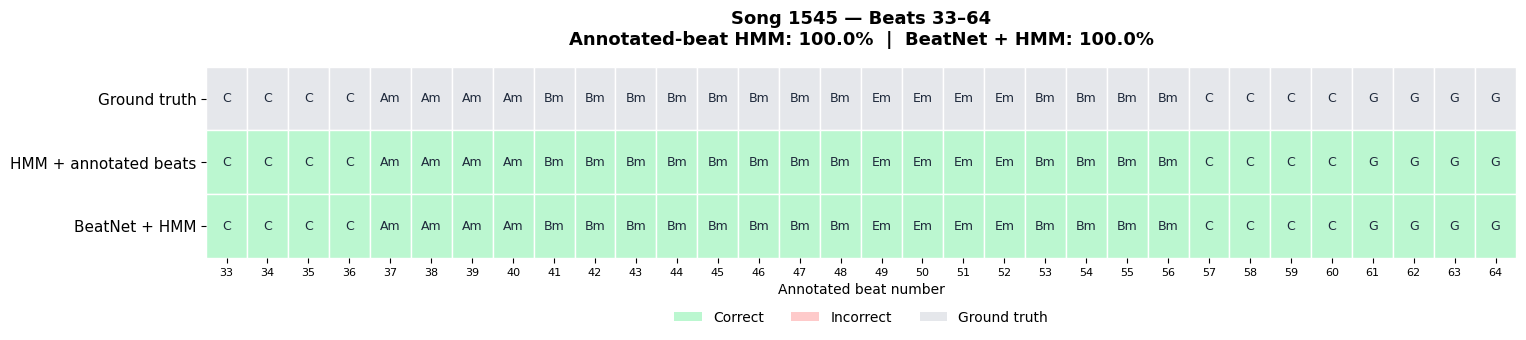

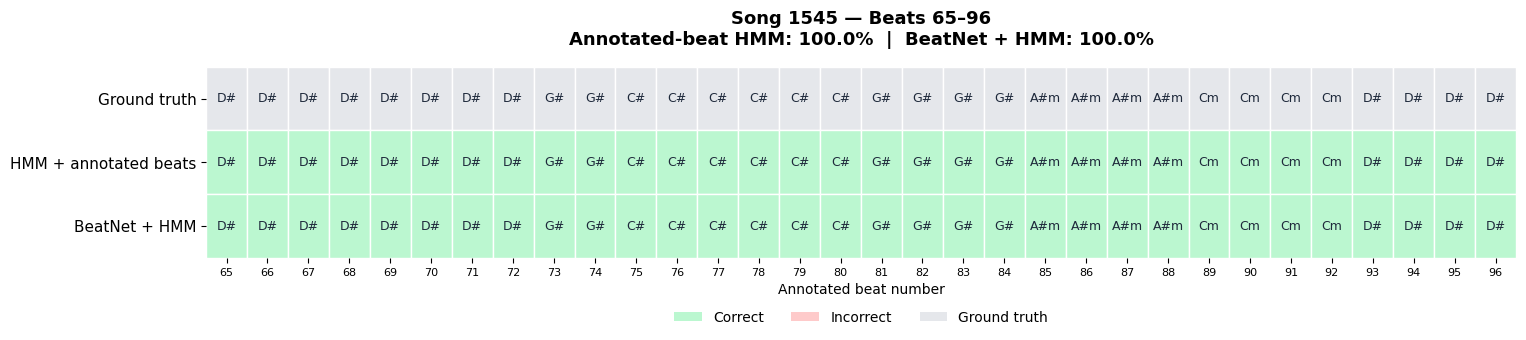

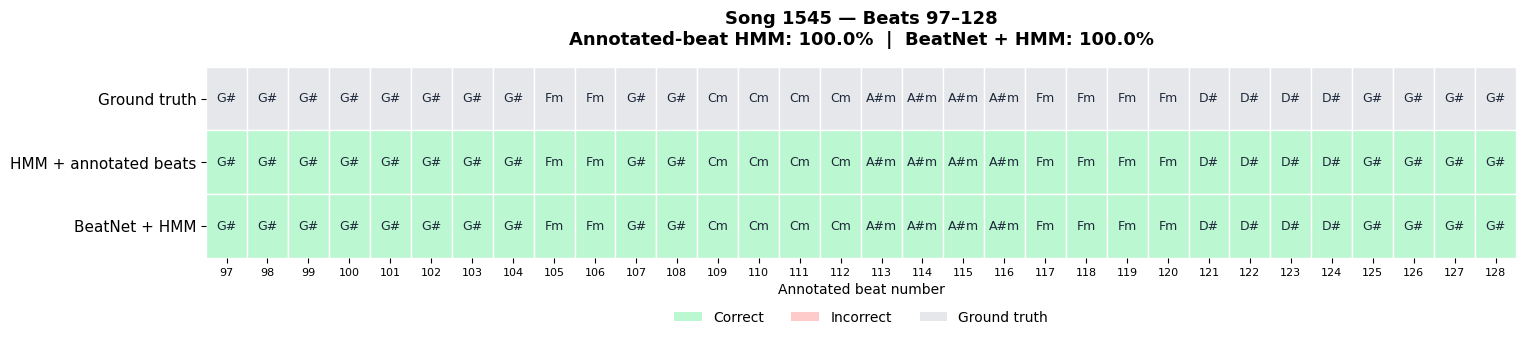

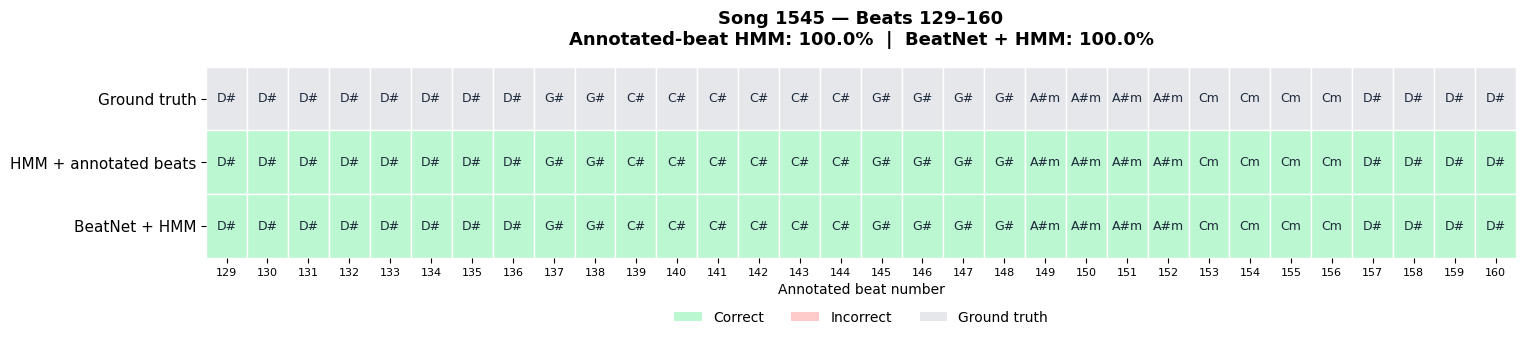

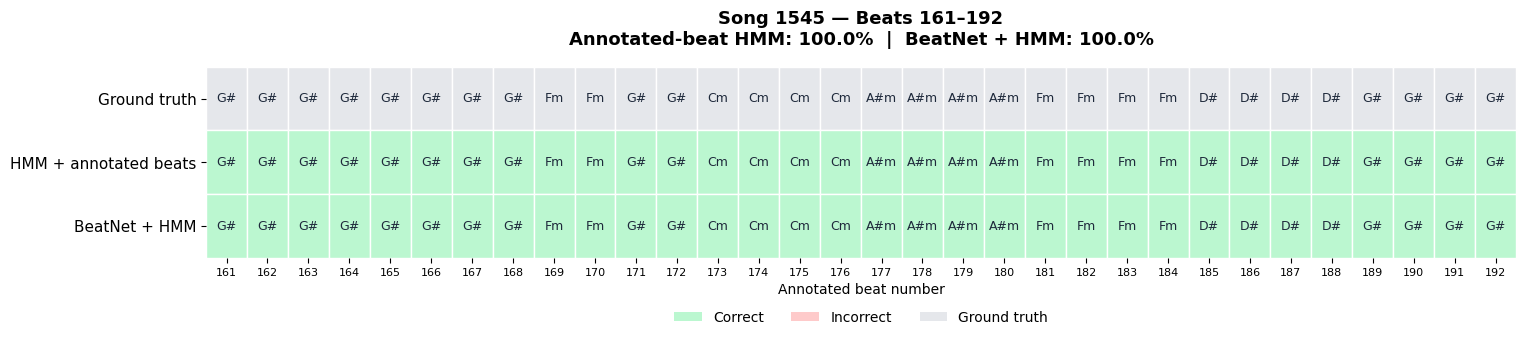

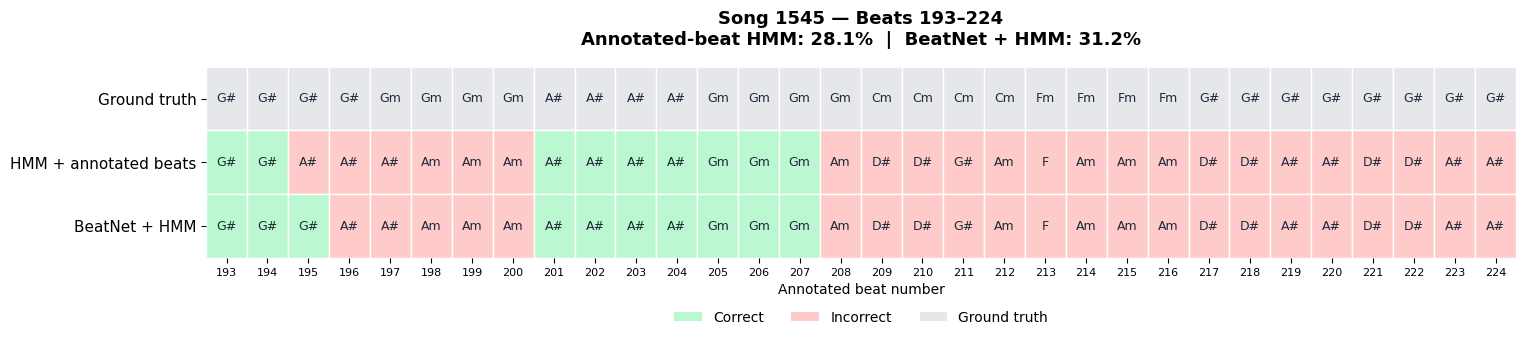

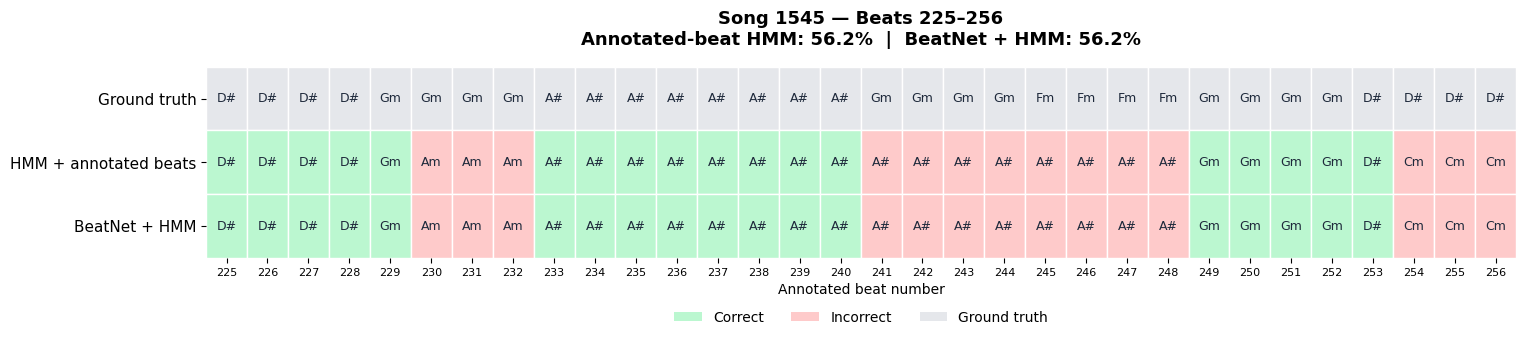


SONG 0080
BeatNet beat F1: 83.6% | Oracle HMM: 98.6% | Full pipeline: 95.2%


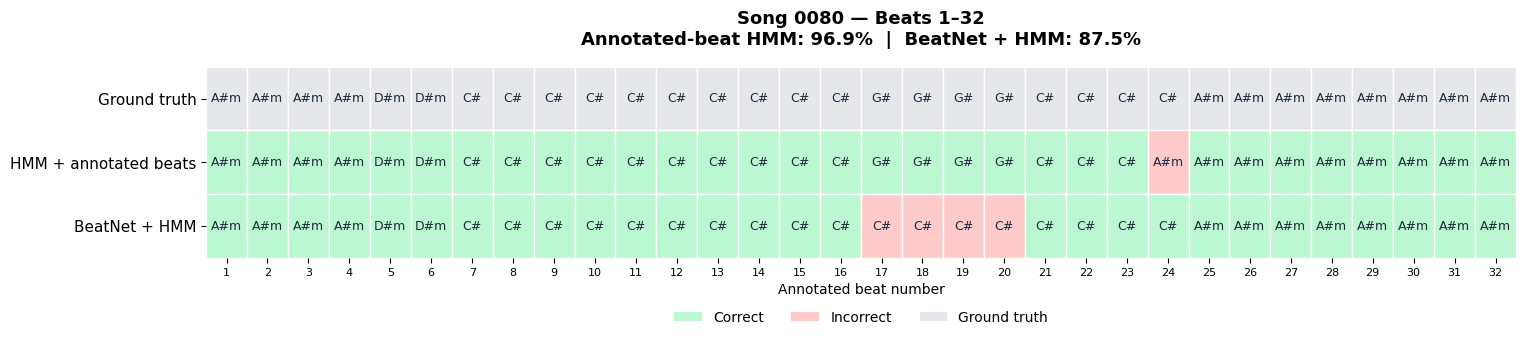

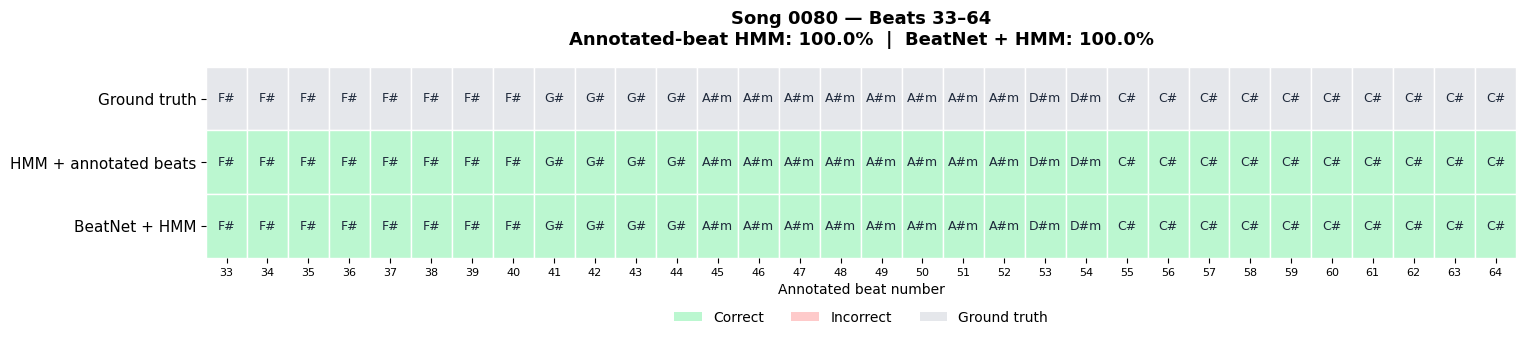

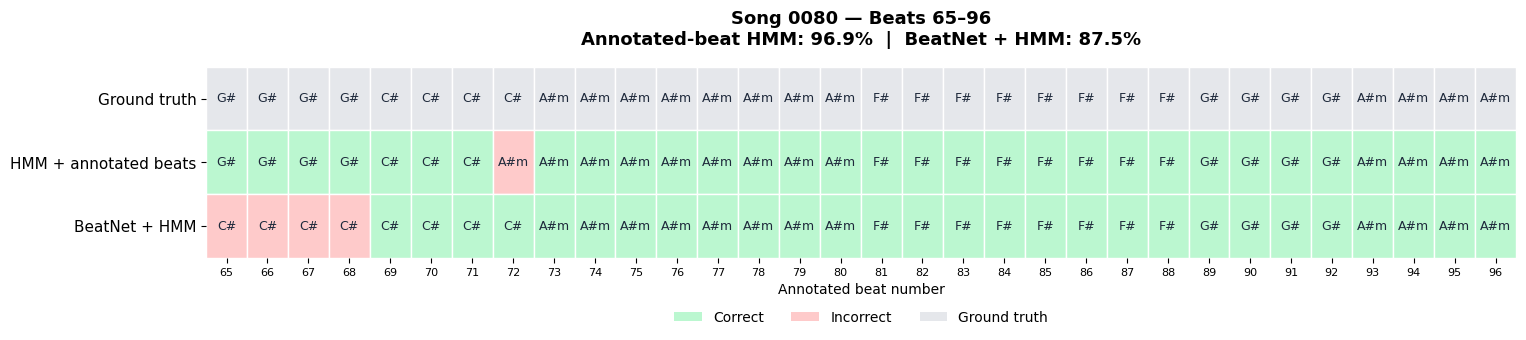

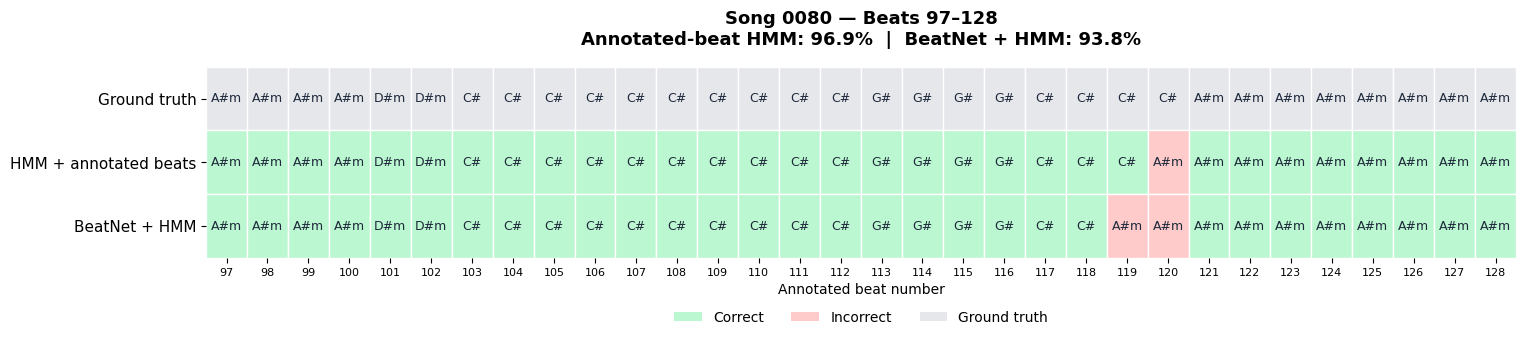

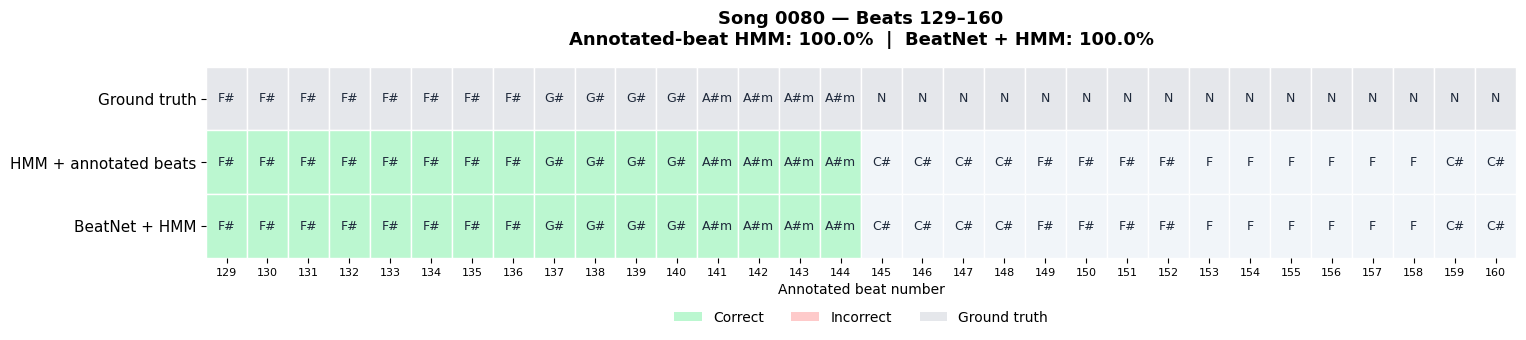

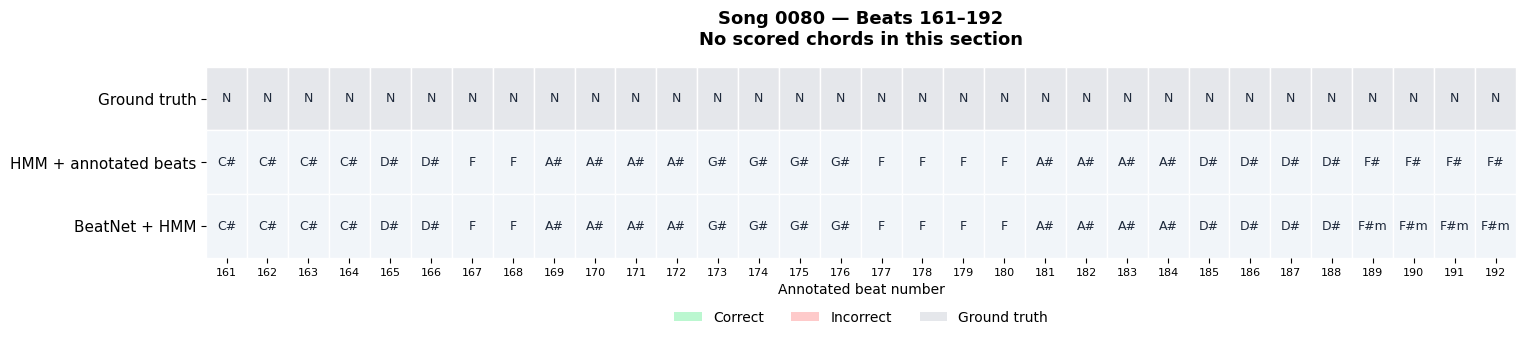

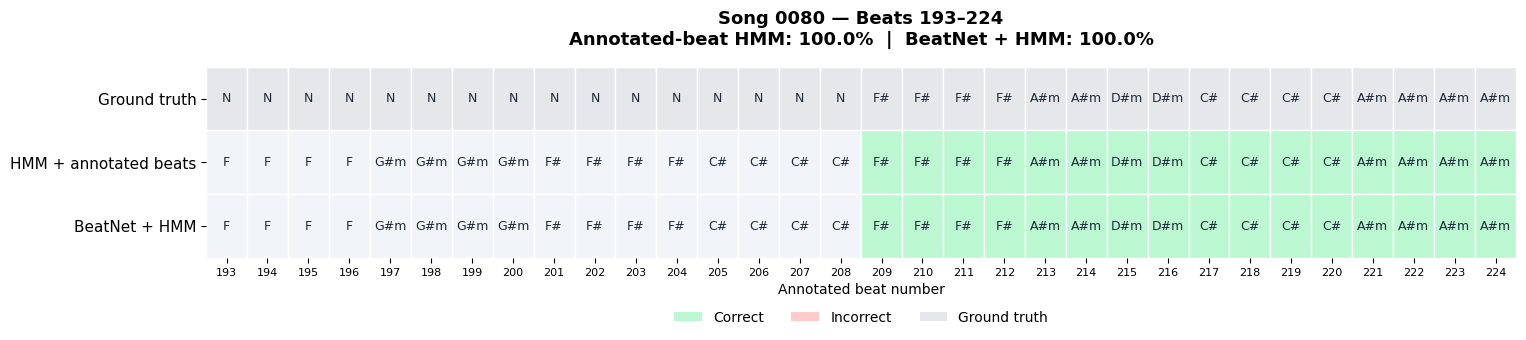

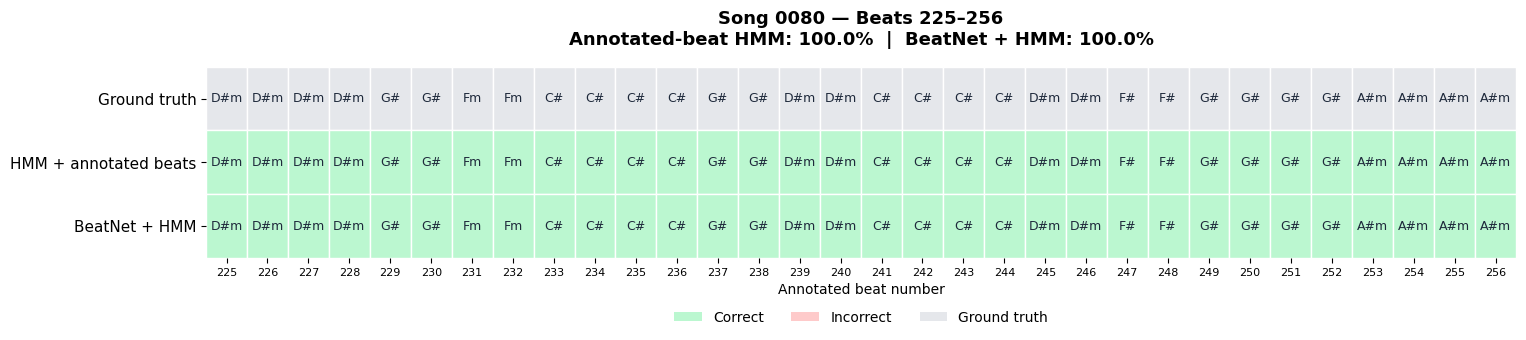


SONG 2841
BeatNet beat F1: 74.7% | Oracle HMM: 98.3% | Full pipeline: 96.0%


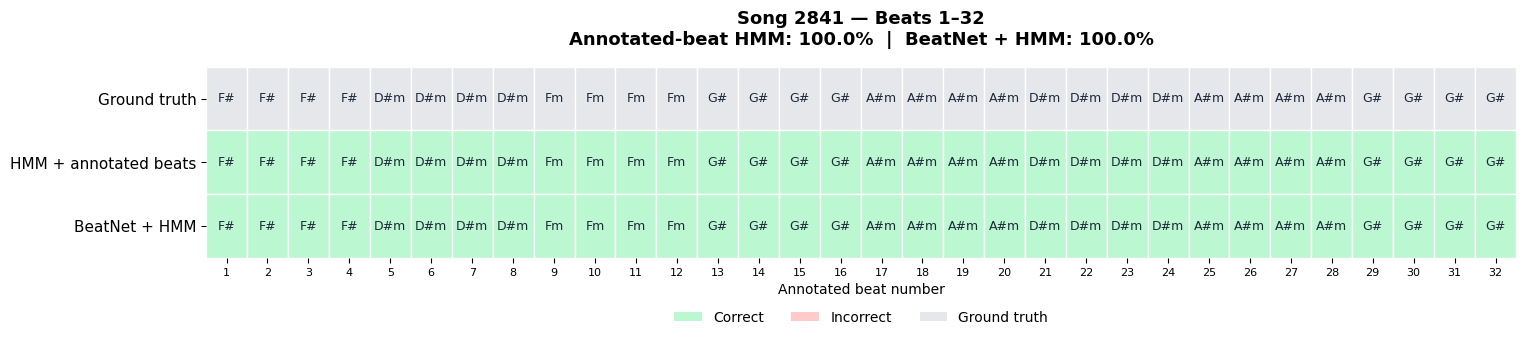

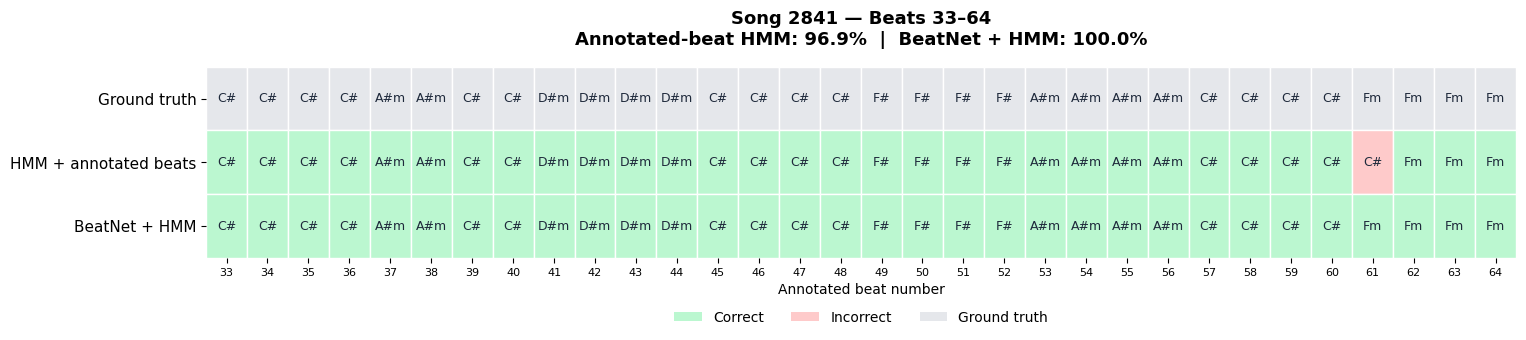

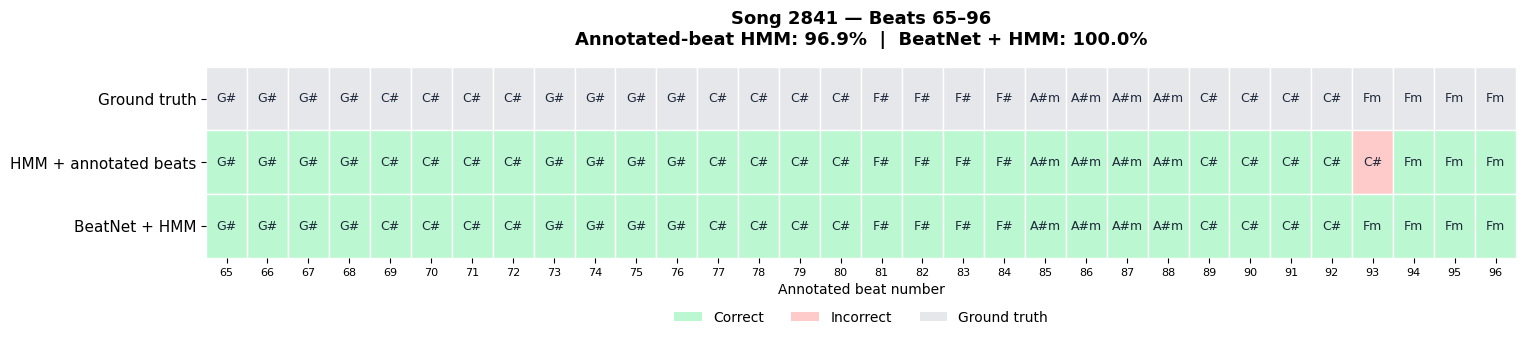

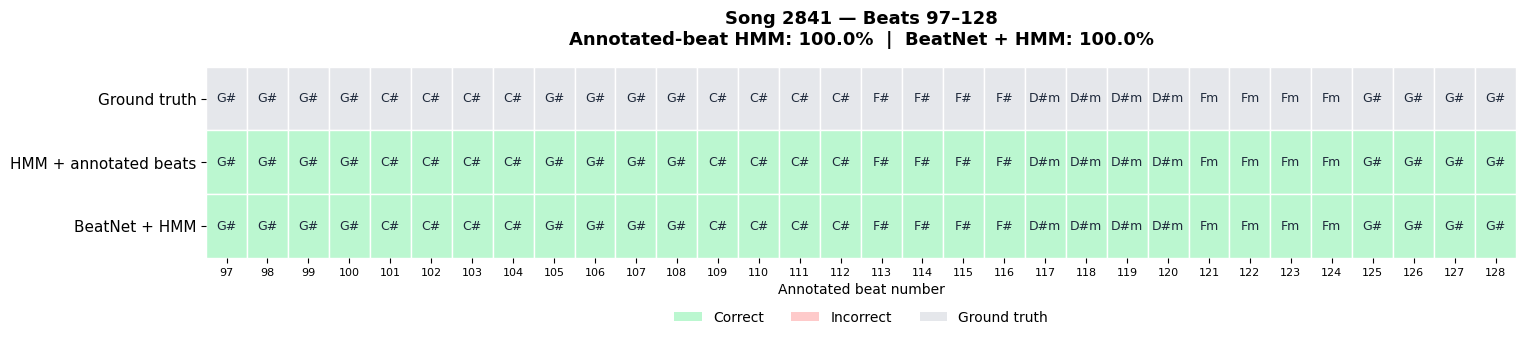

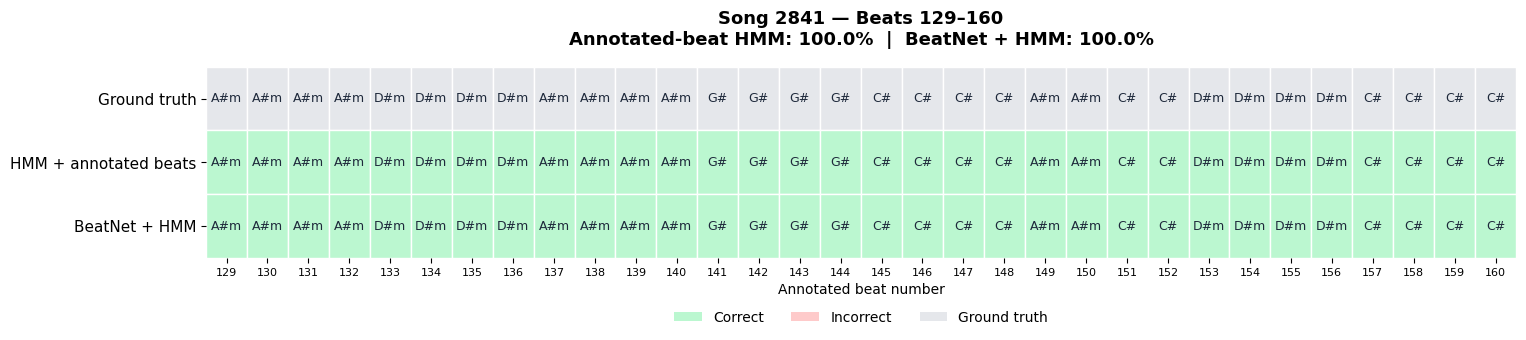

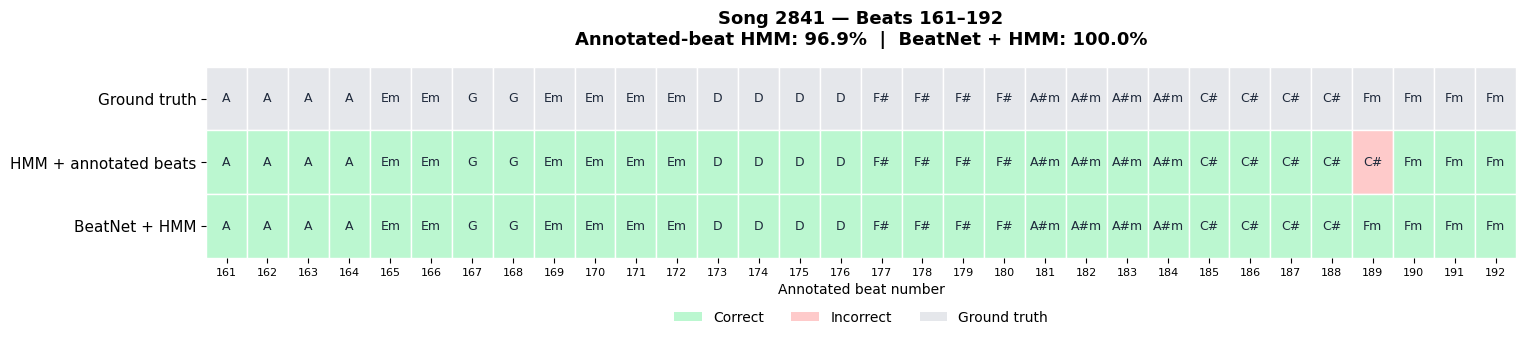

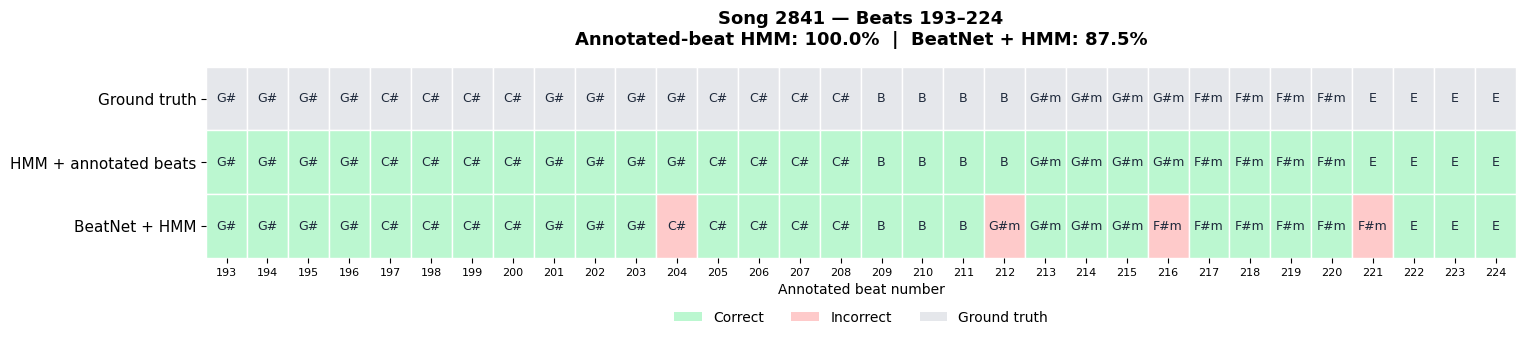

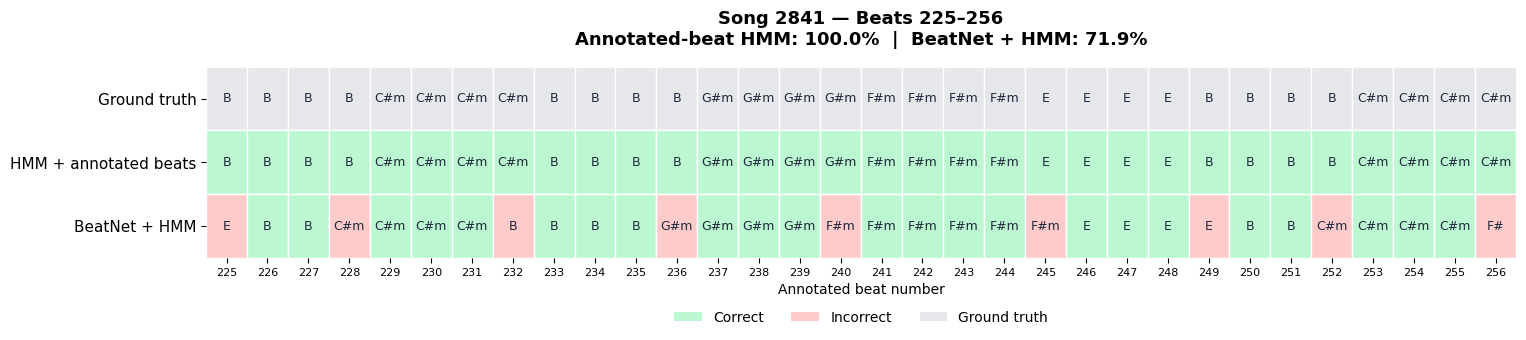

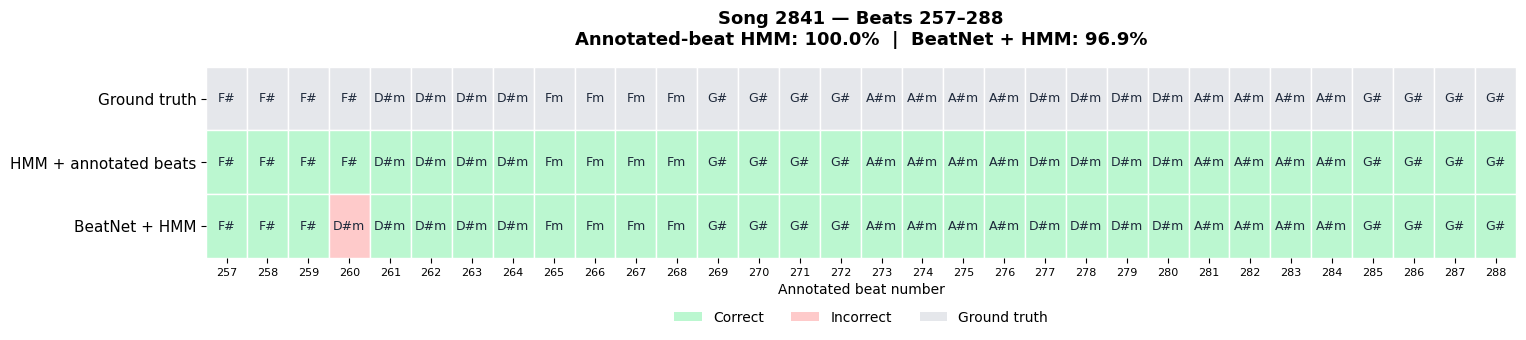

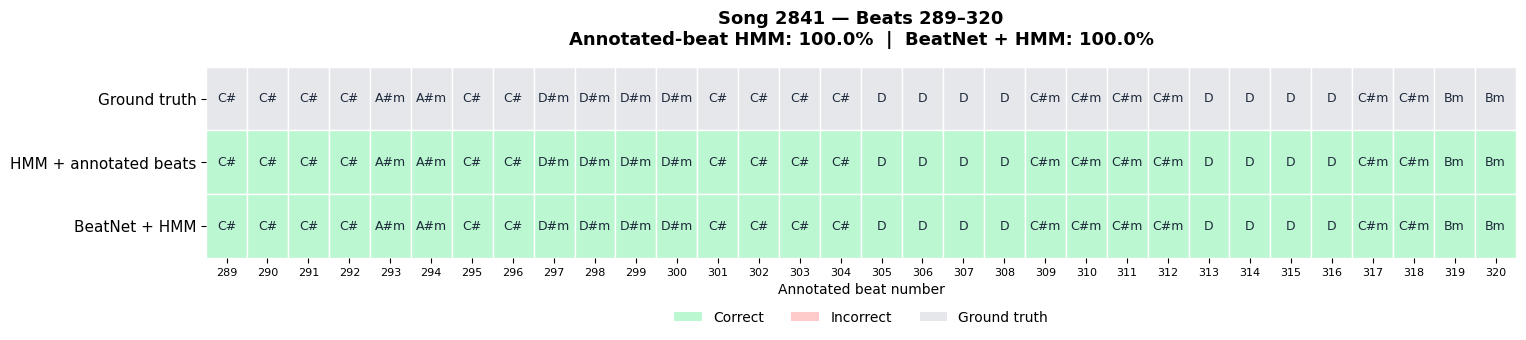

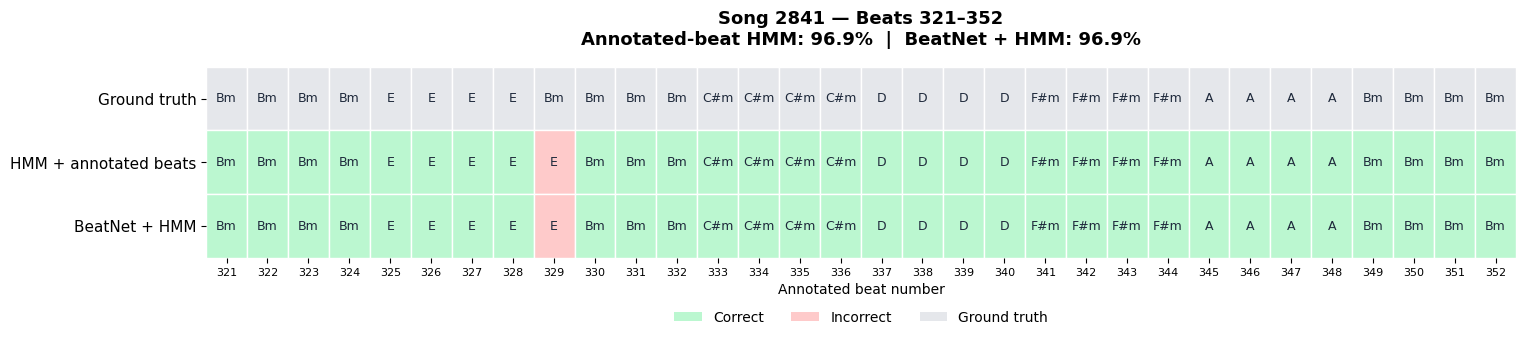

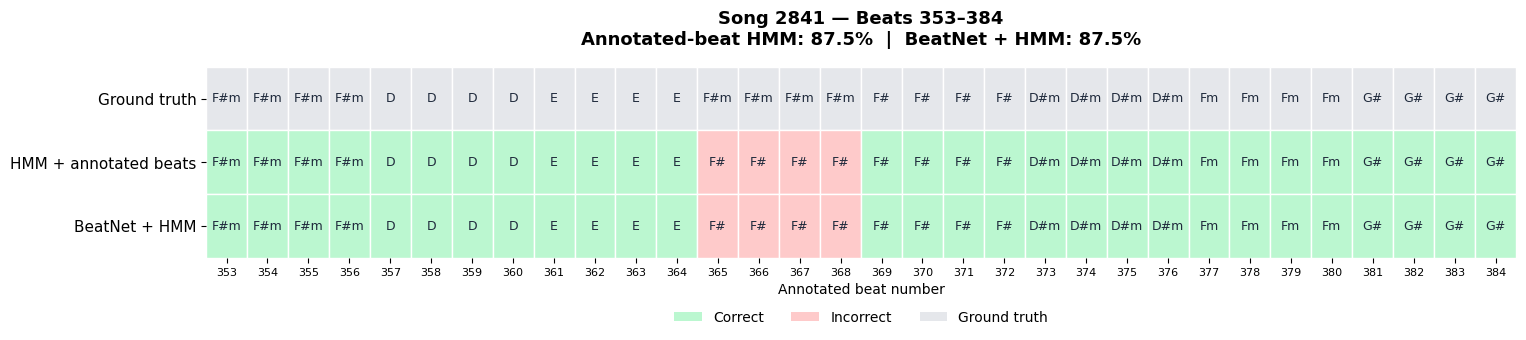

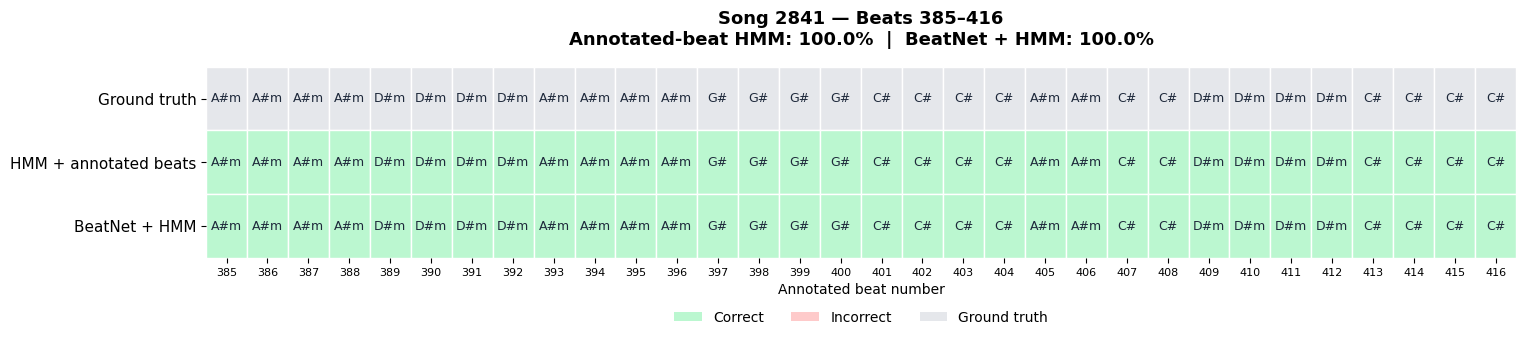

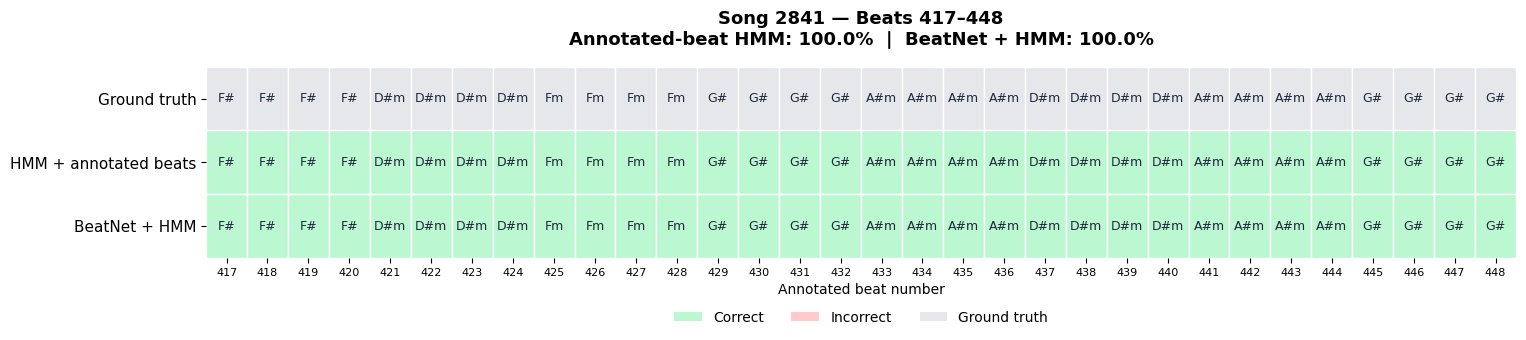

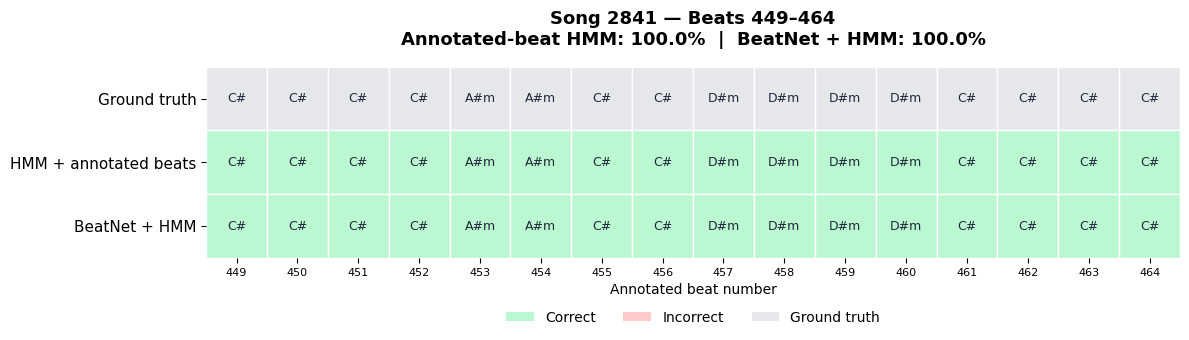


END-TO-END PERFORMANCE SUMMARY


,Song,BeatNet beat F1,HMM with annotated beats,BeatNet + HMM (time aligned),BeatNet prediction coverage
0,1545,99.8%,82.4%,82.5%,100.0%
1,0080,83.6%,98.6%,95.2%,100.0%
2,2841,74.7%,98.3%,96.0%,100.0%


In [14]:

# ============================================================
# CHORD GRID VISUALIZATION — FULL SONG + CLOSE-UP
# Ground truth vs HMM vs BeatNet + HMM
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch
from IPython.display import display

# Presentation colors
CORRECT = "#BBF7D0"
INCORRECT = "#FECACA"
GROUND_TRUTH = "#E5E7EB"
UNSCORED = "#F1F5F9"
TEXT_COLOR = "#1E293B"

BEATS_PER_SECTION = 32


def short_chord(chord):
    """Short readable chord names."""
    return str(chord).replace("maj", "").replace("min", "m")


def align_predictions_to_gt(r):
    """
    Align both models to ground-truth beat intervals.

    For BeatNet, choose the chord covering the midpoint
    of each annotated beat.

    Note: predictions outside BeatNet coverage become N.
    """

    gt_start = np.asarray(r["gt_start"], dtype=float)
    gt_end = np.asarray(r["gt_end"], dtype=float)
    gt = np.asarray(r["gt"], dtype=str)

    oracle = np.asarray(r["oracle"], dtype=str)

    pred_start = np.asarray(r["pred_start"], dtype=float)
    pred_end = np.asarray(r["pred_end"], dtype=float)
    pred = np.asarray(r["pred"], dtype=str)

    midpoints = (gt_start + gt_end) / 2

    indices = np.searchsorted(
        pred_start, midpoints, side="right"
    ) - 1

    aligned = np.full(len(gt), "N", dtype=object)

    for i, idx in enumerate(indices):
        if (
            idx >= 0
            and idx < len(pred)
            and midpoints[i] < pred_end[idx]
        ):
            aligned[i] = pred[idx]

    return gt, oracle, aligned


def plot_chord_grid(r, start_beat=0, n_beats=32):
    """
    Draw a chord-by-chord comparison for one section.

    Each column = one annotated beat.
    Each row = ground truth or a model prediction.
    """

    gt, oracle, beatnet = align_predictions_to_gt(r)

    end_beat = min(start_beat + n_beats, len(gt))

    if start_beat >= end_beat:
        return

    tracks = [
        ("Ground truth", gt[start_beat:end_beat]),
        ("HMM + annotated beats", oracle[start_beat:end_beat]),
        ("BeatNet + HMM", beatnet[start_beat:end_beat]),
    ]

    n = end_beat - start_beat

    fig, ax = plt.subplots(
        figsize=(max(12, n * 0.48), 3.7)
    )

    for row_idx, (name, chords) in enumerate(tracks):

        for beat_idx, chord in enumerate(chords):

            true_chord = tracks[0][1][beat_idx]

            if row_idx == 0:
                color = GROUND_TRUTH

            elif true_chord not in CHORDS2:
                color = UNSCORED

            elif chord == true_chord:
                color = CORRECT

            else:
                color = INCORRECT

            ax.add_patch(
                Rectangle(
                    (beat_idx, row_idx),
                    1, 1,
                    facecolor=color,
                    edgecolor="white",
                    linewidth=1
                )
            )

            ax.text(
                beat_idx + 0.5,
                row_idx + 0.5,
                short_chord(chord),
                ha="center",
                va="center",
                fontsize=9,
                color=TEXT_COLOR
            )

    ax.set_xlim(0, n)
    ax.set_ylim(0, 3)
    ax.invert_yaxis()

    ax.set_yticks(np.arange(3) + 0.5)
    ax.set_yticklabels(
        [name for name, _ in tracks],
        fontsize=11
    )

    ax.set_xticks(np.arange(n) + 0.5)
    ax.set_xticklabels(
        np.arange(start_beat + 1, end_beat + 1),
        fontsize=8
    )

    ax.set_xlabel("Annotated beat number")

    # Accuracy for this displayed section only
    section_gt = tracks[0][1]
    valid = np.isin(section_gt, CHORDS2)

    if valid.any():
        oracle_acc = np.mean(
            tracks[1][1][valid] == section_gt[valid]
        )
        beatnet_acc = np.mean(
            tracks[2][1][valid] == section_gt[valid]
        )

        subtitle = (
            f"Annotated-beat HMM: {oracle_acc:.1%}  |  "
            f"BeatNet + HMM: {beatnet_acc:.1%}"
        )
    else:
        subtitle = "No scored chords in this section"

    ax.set_title(
        f"Song {r['song']} — Beats "
        f"{start_beat + 1}–{end_beat}\n"
        f"{subtitle}",
        fontsize=13,
        fontweight="bold",
        pad=16
    )

    ax.legend(
        handles=[
            Patch(facecolor=CORRECT, label="Correct"),
            Patch(facecolor=INCORRECT, label="Incorrect"),
            Patch(facecolor=GROUND_TRUTH, label="Ground truth"),
        ],
        loc="upper center",
        bbox_to_anchor=(0.5, -0.21),
        ncol=3,
        frameon=False
    )

    ax.spines[:].set_visible(False)

    plt.tight_layout()

    filename = (
        FIG_CACHE /
        f"{MODEL_CHOICE}_{r['song']}_"
        f"beats_{start_beat+1}_{end_beat}.png"
    )

    plt.savefig(filename, dpi=180, bbox_inches="tight")
    plt.show()


# ------------------------------------------------------------
# Full-song chord grids
# ------------------------------------------------------------

def show_results():

    rows = []

    for r in RESULTS:

        gt, oracle, beatnet = align_predictions_to_gt(r)

        print("\n" + "=" * 65)
        print(f"SONG {r['song']}")
        print("=" * 65)

        print(
            f"BeatNet beat F1: {r['beat_f1']:.1%} | "
            f"Oracle HMM: {r['oracle_accuracy']:.1%} | "
            f"Full pipeline: {r['end_to_end_accuracy']:.1%}"
        )

        # Show ALL beats in readable sections
        for start in range(0, len(gt), BEATS_PER_SECTION):
            plot_chord_grid(
                r,
                start_beat=start,
                n_beats=BEATS_PER_SECTION
            )

        rows.append({
            "Song": r["song"],
            "BeatNet beat F1": r["beat_f1"],
            "HMM with annotated beats": r["oracle_accuracy"],
            "BeatNet + HMM (time aligned)": r["end_to_end_accuracy"],
            "BeatNet prediction coverage": r["coverage"]
        })

    summary = pd.DataFrame(rows)

    print("\n" + "=" * 65)
    print("END-TO-END PERFORMANCE SUMMARY")
    print("=" * 65)

    display(
        summary.style.format({
            k: "{:.1%}"
            for k in summary.columns
            if k != "Song"
        })
    )

    summary.to_csv(
        RESULT_CACHE / "demo_metrics.csv",
        index=False
    )

    return summary


summary = show_results()


## 13. Tiny AAM test-set chord benchmark

This uses the annotated-beat grid only and measures the baseline Gaussian versus HMM on all held-out Tiny AAM songs. Unlike the BeatNet end-to-end metric above, it is per annotated beat. No held-out labels were used for training or choosing the HMM weight.

In [ ]:
def benchmark_on_test(model, songs):
    gauss=model['gaussian'];A=model['transition']['A'];w=model['learned_weight']
    true=[];base=[];learned=[]
    for song in songs:
        d=extract_features(song)
        valid=np.isin(d['gt'],CHORDS2)
        if not valid.any():continue
        scores=emission_scores(d['X'],gauss)
        true.extend(d['gt'][valid]);base.extend(CHORDS2[np.argmax(scores,axis=1)][valid]);
        learned.extend(CHORDS2[viterbi(scores,A,w)][valid])
    return pd.DataFrame([{'Model':'Gaussian only','Beat accuracy':accuracy_score(true,base),
        'Macro F1':f1_score(true,base,labels=CHORDS2,average='macro',zero_division=0)},
        {'Model':'Learned HMM + Viterbi','Beat accuracy':accuracy_score(true,learned),
         'Macro F1':f1_score(true,learned,labels=CHORDS2,average='macro',zero_division=0)}])

benchmark=benchmark_on_test(tiny_model,test_ids)
display(benchmark.style.format({'Beat accuracy':'{:.1%}','Macro F1':'{:.3f}'}))

---
# OPTIONAL — Train on more AAM songs

**Stop here if you only want the Tiny AAM demonstration.** The previous cells run independently of this section.

This optional section accesses Zenodo's **AAM 0001–1000 archive**, not the full 3,000-song collection. Choose `N_FULL_TRAIN` between 10 and the number of eligible songs in that archive. This notebook does *not* pretend to support all 3,000 songs from one archive: additional archives would need to be added explicitly.

To avoid test leakage, **all Tiny AAM song IDs are excluded from the larger training set**. The existing Tiny AAM demo/test songs remain a distinct evaluation set. Validation for the larger model also uses different non-Tiny AAM songs, and the chosen weight is tuned on them. Downloading the full annotations ZIP and opening the remote audio ZIP can take longer and may be affected by temporary Zenodo 504 errors.

Change `N_FULL_TRAIN`, run the optional cells, and switch `MODEL_CHOICE='larger'` in the selection cell. You can rerun `run_demo()` and `show_results()` without changing the beat detection or feature code.

## 14. Optional large-dataset configuration and annotation/audio access

In [ ]:
RUN_LARGER_TRAINING = False  # Set True to enable this entire OPTIONAL section.
N_FULL_TRAIN = 80             # Examples: 10, 80, 250, 500 (within 0001–1000)
N_FULL_VAL = 20               # Dedicated validation tracks for weight selection

if RUN_LARGER_TRAINING:
    from remotezip import RemoteZip
    import requests
    BASE='https://zenodo.org/records/5794629/files'
    ANN_URL=BASE+'/0001-1000-annotations-v1.1.0.zip?download=1'
    AUD_URL=BASE+'/0001-1000-audio-mixes.zip?download=1'
    full_annotations_zip=CACHE/'0001-1000-annotations-v1.1.0.zip'
    if not full_annotations_zip.exists() or not zipfile.is_zipfile(full_annotations_zip):
        temp=full_annotations_zip.with_suffix('.part')
        for attempt in range(3):
            try:
                with requests.get(ANN_URL,timeout=(30,180),stream=True) as resp:
                    resp.raise_for_status()
                    with open(temp,'wb') as f:
                        for chunk in resp.iter_content(1024*1024):
                            if chunk:f.write(chunk)
                temp.replace(full_annotations_zip)
                break
            except Exception:
                temp.unlink(missing_ok=True)
                if attempt==2:raise
                time.sleep(5*(attempt+1))
    ann_zip_full=zipfile.ZipFile(full_annotations_zip)
    ann_members_full={}
    for name in ann_zip_full.namelist():
        m=re.search(r'(?:^|/)(\d{4})_beatinfo\.arff$',name,re.I)
        if m:ann_members_full[m.group(1)]=name
    print('Opening large audio archive with RemoteZip...')
    for attempt in range(3):
        try:
            audio_zip_full=RemoteZip(AUD_URL)
            audio_members_full={}
            for name in audio_zip_full.namelist():
                m=re.search(r'(?:^|/)(\d{4})_mix\.(?:flac|mp3|wav)$',name,re.I)
                if m:audio_members_full[m.group(1)]=name
            break
        except Exception:
            if attempt==2:raise
            time.sleep(5*(attempt+1))
    candidates=sorted((set(ann_members_full)&set(audio_members_full))-set(TINY_IDS))
    if N_FULL_TRAIN+N_FULL_VAL>len(candidates):
        raise ValueError(f'Requested {N_FULL_TRAIN+N_FULL_VAL} tracks, but only {len(candidates)} eligible non-Tiny tracks.')
    rng=np.random.default_rng(SEED)
    shuffled=rng.permutation(candidates).tolist()
    full_train_ids=shuffled[:N_FULL_TRAIN]
    full_val_ids=shuffled[N_FULL_TRAIN:N_FULL_TRAIN+N_FULL_VAL]
    # Extend annotations but keep Tiny test IDs entirely separate.
    larger_ann=prepare_ann_data({s:ann_zip_full.read(ann_members_full[s])
        for s in full_train_ids+full_val_ids})
    ann_data.update(larger_ann)
    FULL_AUDIO_CACHE=CACHE/'full_audio';FULL_AUDIO_CACHE.mkdir(exist_ok=True)

    def load_full_audio(song):
        member=audio_members_full[song]
        target=FULL_AUDIO_CACHE/f'{song}{Path(member).suffix}'
        if not target.exists():
            tmp=target.with_suffix('.part')
            for attempt in range(3):
                try:
                    with audio_zip_full.open(member) as source,open(tmp,'wb') as dest:
                        shutil.copyfileobj(source,dest,length=1024*1024)
                    tmp.replace(target);break
                except Exception:
                    tmp.unlink(missing_ok=True)
                    if attempt==2:raise
                    time.sleep(4*(attempt+1))
        return librosa.load(str(target),sr=SR,mono=True)[0]
    print('Larger training songs:',len(full_train_ids),'validation:',len(full_val_ids))
    print('All Tiny AAM songs excluded from larger training/validation:',not (set(TINY_IDS)&set(full_train_ids+full_val_ids)))
else:
    print('Optional larger dataset access skipped — Tiny AAM demo remains ready.')

## 15. Optional: fit larger model, checkpoint separately, and switch models

Only run after enabling the preceding cell. **Separate saved checkpoint per song count**, so changing the number of training songs does not overwrite the Tiny AAM model. Larger model weights are tuned only on the separate large-AAM validation partition.

In [ ]:
if RUN_LARGER_TRAINING:
    LARGE_CHECKPOINT=MODEL_DIR/f'larger_gaussian_hmm_train{N_FULL_TRAIN}_val{N_FULL_VAL}_seed{SEED}.pkl'
    if LARGE_CHECKPOINT.exists():
        with open(LARGE_CHECKPOINT,'rb') as f:larger_model=pickle.load(f)
        if larger_model['training_songs']!=full_train_ids or larger_model['validation_songs']!=full_val_ids:
            raise RuntimeError('Saved larger checkpoint incompatible with current song selection.')
        print('Loaded larger model:',LARGE_CHECKPOINT)
    else:
        started=time.time()
        larger_gaussian=fit_gaussian_emissions(full_train_ids)
        larger_transition=learn_relative_transitions(full_train_ids,smoothing=.5)
        larger_weight,larger_val_grid=choose_weight(larger_gaussian,larger_transition['A'],full_val_ids)
        larger_model=dict(gaussian=larger_gaussian,transition=larger_transition,
            learned_weight=float(larger_weight),validation_grid=larger_val_grid,
            training_songs=list(full_train_ids),validation_songs=list(full_val_ids),
            test_songs=list(test_ids),chords=CHORDS2.copy(),sr=SR,hop=HOP)
        tmp=LARGE_CHECKPOINT.with_suffix('.tmp')
        with open(tmp,'wb') as f:pickle.dump(larger_model,f)
        tmp.replace(LARGE_CHECKPOINT)
        print(f'Saved larger model after {(time.time()-started)/60:.1f} minutes:',LARGE_CHECKPOINT)
    print('Larger model validation transition weight:',larger_model['learned_weight'])
else:
    print('Larger training disabled; nothing to do.')

## 16. Choose Tiny or larger model, then rerun the same demo

Set `MODEL_CHOICE` to `tiny` or `larger`. Larger requires the optional training cells above. All held-out Tiny AAM demo songs stay unchanged, so model comparisons are on the same songs. BeatNet results are cached and will not be rerun unnecessarily.

In [ ]:
MODEL_CHOICE = 'tiny'  # 'tiny' or 'larger'
if MODEL_CHOICE == 'tiny':
    ACTIVE_MODEL=tiny_model
elif MODEL_CHOICE == 'larger':
    if 'larger_model' not in globals():
        raise RuntimeError('Train/load the optional larger model in section 15 first.')
    ACTIVE_MODEL=larger_model
else:
    raise ValueError("MODEL_CHOICE must be 'tiny' or 'larger'")
GAUSSIAN=ACTIVE_MODEL['gaussian']
A_LEARNED=ACTIVE_MODEL['transition']['A']
WEIGHT=ACTIVE_MODEL['learned_weight']
print(f'Active: {MODEL_CHOICE}, trained on {len(ACTIVE_MODEL["training_songs"])} songs, weight {WEIGHT}')
# Re-run the exact same held-out Tiny AAM songs using cached BeatNet estimates.
run_demo()
summary=show_results()
display(benchmark_on_test(ACTIVE_MODEL,test_ids).style.format({'Beat accuracy':'{:.1%}','Macro F1':'{:.3f}'}))

## Summary and limitations

- **No end-to-end accuracy is claimed until this notebook runs.** The Tiny AAM demonstration will be smaller and noisier than the earlier 80-song result.
- The HMM uses 24 major/minor chord classes only; unsupported labels are unscored.
- The test uses automatic BeatNet times and compares the resulting chord timeline against actual chord annotation times. The annotated-beat evaluation is shown separately.
- BeatNet may run at half/double tempo or choose a shifted beat phase. The timeline comparison exposes those errors.
- The transition model pools chord movements across keys, which gains statistical efficiency but **does not model key-dependent I/IV/V harmonic function**.
- Larger-AAM access is optional, and the notebook currently covers the `0001–1000` archive. Additional archive batches are a separate extension.

**Next improvements:** chord-change boundary evaluation, explicit duration models / chord-event sequence, key-aware transitions, and extended chords.